# Physician office visits for a Medicare beneficiary

A plan that prices an annual physician-office-visit allowance sees the person at enrollment, not their other care during the year. The response is the count of physician office visits. Same-year hospital stays, emergency visits, and non-physician visits are co-outcomes, so they are not predictors.

The file is the NMES 1987/88 Medicare subsample aged 66 and over, 4,406 people, as distributed by the R package AER (`NMES1988`) from the Journal of Applied Econometrics archive for Deb and Trivedi (1997). The CSV is the Rdatasets mirror of that frame, retrieved 2026-10-04 from `https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/AER/NMES1988.csv`. The R row index is dropped. The columns are the mean specification in Zeileis, Kleiber and Jackman (2008, JSS 27(8)): self-reported health, number of chronic conditions, gender, years of school, and private insurance. Age in the source file is years divided by 10; it is not in this specification.

The decision is which distribution to publish for that count. A Poisson GLM is the default count regression. The visits are overdispersed (variance well above the mean, and about 15% zeros against a Poisson probability near zero at a mean of about 6), so a negative binomial and a zero-inflated Poisson are the alternatives a pricing desk would actually fit. A Gaussian linear model is the installed-package baseline that ignores the count support. Boosting uses the same linear specification. Steps are chosen on held-out people, not on a later year: this is one cross-section.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | annual physician office visits for a Medicare beneficiary |
| **Observed response** | `visits`, a non-negative integer count |
| **Estimand** | held-out mean absolute error of the mean, and the mean negative log probability of the count |
| **Units** | visits; nats per person |
| **Sampling unit** | one row is one Medicare beneficiary with an annual office-visit count |
| **Dependence** | The working likelihood treats beneficiary records as conditionally independent; no cluster adjustment is estimated. |
| **Split and tuning** | people, stratified by self-reported health; 20% to choose boosting steps, 20% held out, refit on the rest |
| **Information** | chronic conditions, years of school, health (average as the reference), gender (female as the reference), private insurance |
| **Uncertainty** | fitted predictive distributions are scored; no resampling confidence intervals for score differences are reported |
| **Claim type** | predictive comparisons conditional on the recorded covariates; no causal effects are estimated |
| **What this does not estimate** | a causal effect of insurance or schooling, a forecast for a later year, or the distribution of hospital stays |

:::


In [1]:
import warnings
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats

import mboostrs as mb

csv_path = Path("nmes1988_visits.csv")
if not csv_path.exists():
    csv_path = Path("docs/book/case_studies/nmes1988_visits.csv")
raw = pl.read_csv(csv_path, comment_prefix="#")
frame = raw.with_columns(
    (pl.col("health") == "poor").cast(pl.Float64).alias("health_poor"),
    (pl.col("health") == "excellent").cast(pl.Float64).alias("health_excellent"),
    (pl.col("gender") == "male").cast(pl.Float64).alias("gender_male"),
    (pl.col("insurance") == "yes").cast(pl.Float64).alias("insurance_yes"),
    pl.col("chronic").cast(pl.Float64),
    pl.col("school").cast(pl.Float64),
    pl.col("visits").cast(pl.Float64),
)
formula = (
    "visits ~ chronic + school + health_poor + health_excellent + gender_male + insurance_yes"
)

rng = np.random.default_rng(20261004)
indexed = frame.with_row_index("i")
parts = []
for level in sorted(frame["health"].unique().to_list()):
    ids = indexed.filter(pl.col("health") == level)["i"].to_numpy().copy()
    rng.shuffle(ids)
    n = len(ids)
    n_test = int(round(0.20 * n))
    n_valid = int(round(0.20 * n))
    parts.append((ids[n_test + n_valid :], ids[n_test : n_test + n_valid], ids[:n_test]))
train_ids = np.concatenate([p[0] for p in parts])
valid_ids = np.concatenate([p[1] for p in parts])
test_ids = np.concatenate([p[2] for p in parts])
train = frame[train_ids.tolist()]
valid = frame[valid_ids.tolist()]
fit_rows = frame[np.concatenate([train_ids, valid_ids]).tolist()]
test = frame[test_ids.tolist()]
y_test = test["visits"].to_numpy()
zero_share = float((y_test == 0).mean())
print(
    f"{frame.height} people, {train.height} to fit the path, {valid.height} to choose steps, "
    f"{fit_rows.height} refit, {test.height} held out; "
    f"mean {float(frame['visits'].mean()):.2f}, variance {float(frame['visits'].var()):.1f}, "
    f"zeros {float((frame['visits'] == 0).mean()):.3f}"
)

4406 people, 2642 to fit the path, 882 to choose steps, 3524 refit, 882 held out; mean 5.77, variance 45.7, zeros 0.155


In [2]:
def columns_of(data):
    return {name: data[name].to_numpy() for name in data.columns}


def poisson_nll(y, mu):
    return float(-stats.poisson.logpmf(y, np.clip(mu, 1e-8, None)).mean())


def nbinom_nll(y, mu, size):
    mu = np.clip(np.asarray(mu, dtype=float), 1e-8, None)
    # size is scipy's n: mean mu, variance mu + mu**2 / size.
    return float(-stats.nbinom.logpmf(y, size, size / (size + mu)).mean())


def gaussian_nll(y, mu, sd):
    return float(-stats.norm.logpdf(y, mu, max(sd, 1e-8)).mean())


with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    poisson = smf.glm(formula, columns_of(fit_rows), family=sm.families.Poisson()).fit()
    ols = smf.ols(formula, columns_of(fit_rows)).fit()
    negbin = smf.negativebinomial(formula, columns_of(fit_rows)).fit(disp=False, maxiter=200)

poisson_mu = np.asarray(poisson.predict(columns_of(test)), dtype=float)
ols_mu = np.asarray(ols.predict(columns_of(test)), dtype=float)
negbin_mu = np.asarray(negbin.predict(columns_of(test)), dtype=float)
negbin_alpha = float(np.exp(negbin.lnalpha))
ols_sd = float(np.sqrt(np.mean((fit_rows["visits"].to_numpy() - ols.predict(columns_of(fit_rows))) ** 2)))
pearson_dispersion = float(poisson.pearson_chi2 / poisson.df_resid)
negbin_converged = bool(negbin.mle_retvals.get("converged"))

In [3]:
def choose_mstop(kind, cap):
    family = {
        "gaussian": mb.Gaussian(),
        "poisson": mb.Poisson(),
        "nb": mb.NBinomial(),
        "zip": mb.ZIPoLSS(),
    }[kind]
    location_scale = kind == "zip"
    kwargs = {"family": family, "control": mb.boost_control(cap, 0.1)}
    if location_scale:
        kwargs["method"] = "noncyclic"
    ctor = mb.glmboostLSS if location_scale else mb.glmboost
    path = ctor(formula, train, **kwargs)
    y_valid = valid["visits"].to_numpy()
    best_step, best_score = None, np.inf
    for step in range(20, cap + 1, 20):
        tuned = path.with_mstop(step)
        pred = tuned.predict(valid, type="response")
        if kind == "gaussian":
            train_mu = np.asarray(tuned.predict(train, type="response"), dtype=float).ravel()
            train_sd = float(np.sqrt(np.mean((train["visits"].to_numpy() - train_mu) ** 2)))
            score = gaussian_nll(y_valid, np.asarray(pred, dtype=float).ravel(), train_sd)
        elif kind == "poisson":
            score = poisson_nll(y_valid, np.asarray(pred, dtype=float).ravel())
        elif kind == "nb":
            size = float(np.asarray(tuned.nuisance()).ravel()[0])
            score = nbinom_nll(y_valid, np.asarray(pred, dtype=float).ravel(), size)
        else:
            mu = np.asarray(pred["mu"], dtype=float).ravel()
            sigma = np.asarray(pred["sigma"], dtype=float).ravel()
            mass = mb.ZIPoLSS().pmf(y_valid, {"mu": mu, "sigma": sigma})
            score = float(-np.log(np.clip(mass, 1e-300, None)).mean())
        if score < best_score:
            best_step, best_score = step, score
    return best_step, best_score, best_step == cap, ctor, family, location_scale


jobs = [
    ("mboostrs glmboost Gaussian", "gaussian", 600),
    ("mboostrs glmboost Poisson", "poisson", 400),
    ("mboostrs glmboost NBinomial", "nb", 600),
    ("mboostrs glmboostLSS ZIPoLSS", "zip", 400),
]
boosted = {}
for label, kind, cap in jobs:
    step, score, at_cap, ctor, family, location_scale = choose_mstop(kind, cap)
    kwargs = {"family": family, "control": mb.boost_control(step, 0.1)}
    if location_scale:
        kwargs["method"] = "noncyclic"
    fitted = ctor(formula, fit_rows, **kwargs)
    boosted[label] = {
        "mstop": step,
        "validation": score,
        "at_cap": at_cap,
        "fit": fitted,
        "pred": fitted.predict(test, type="response"),
        "kind": kind,
    }

In [4]:
rows = []


def add(method, mu, nll, p0, mstop=None, at_cap=None, note=""):
    mu = np.asarray(mu, dtype=float).ravel()
    rows.append({
        "method": method,
        "mae": float(np.mean(np.abs(mu - y_test))),
        "nll": nll,
        "p0": p0,
        "mstop": mstop,
        "at_cap": at_cap,
        "note": note,
    })


add(
    "statsmodels OLS",
    ols_mu,
    gaussian_nll(y_test, ols_mu, ols_sd),
    None,
    note=f"residual sd {ols_sd:.2f}; negative predictions {float((ols_mu < 0).mean()):.3f}",
)
add(
    "statsmodels Poisson GLM",
    poisson_mu,
    poisson_nll(y_test, poisson_mu),
    float(np.mean(np.exp(-poisson_mu))),
    note=f"Pearson dispersion {pearson_dispersion:.2f}",
)
add(
    "statsmodels negative binomial",
    negbin_mu,
    nbinom_nll(y_test, negbin_mu, 1.0 / negbin_alpha),
    float(np.mean((1.0 / negbin_alpha / (1.0 / negbin_alpha + negbin_mu)) ** (1.0 / negbin_alpha))),
    note=f"alpha {negbin_alpha:.3f}, converged {negbin_converged}",
)
for label, item in boosted.items():
    kind, pred, fitted = item["kind"], item["pred"], item["fit"]
    if kind == "gaussian":
        mu = np.asarray(pred, dtype=float).ravel()
        train_mu = np.asarray(fitted.predict(fit_rows, type="response"), dtype=float).ravel()
        sd = float(np.sqrt(np.mean((fit_rows["visits"].to_numpy() - train_mu) ** 2)))
        add(label, mu, gaussian_nll(y_test, mu, sd), None, item["mstop"], item["at_cap"],
            note=f"residual sd {sd:.2f}")
    elif kind == "poisson":
        mu = np.asarray(pred, dtype=float).ravel()
        add(label, mu, poisson_nll(y_test, mu), float(np.mean(np.exp(-mu))),
            item["mstop"], item["at_cap"], note="")
    elif kind == "nb":
        mu = np.asarray(pred, dtype=float).ravel()
        size = float(np.asarray(fitted.nuisance()).ravel()[0])
        p0 = float(np.mean((size / (size + mu)) ** size))
        add(label, mu, nbinom_nll(y_test, mu, size), p0, item["mstop"], item["at_cap"],
            note=f"size {size:.3f}, alpha {1.0 / size:.3f}")
        nb_boost_size = size
    else:
        mu_pois = np.asarray(pred["mu"], dtype=float).ravel()
        sigma = np.asarray(pred["sigma"], dtype=float).ravel()
        mu = (1.0 - sigma) * mu_pois
        mass = mb.ZIPoLSS().pmf(y_test, {"mu": mu_pois, "sigma": sigma})
        nll = float(-np.log(np.clip(mass, 1e-300, None)).mean())
        p0 = float(np.mean(sigma + (1.0 - sigma) * np.exp(-mu_pois)))
        add(label, mu, nll, p0, item["mstop"], item["at_cap"],
            note=f"mean zero-inflation {float(sigma.mean()):.3f}")
        zip_sigma = float(sigma.mean())

summary = pl.DataFrame(rows).sort("nll")
display(summary)
print("held-out share with zero visits", round(zero_share, 3))

method,mae,nll,p0,mstop,at_cap,note
str,f64,f64,f64,i64,bool,str
"""statsmodels negative binomial""",3.940594,2.739451,0.141496,null,null,"""alpha 0.876, converged True"""
"""mboostrs glmboost NBinomial""",3.944938,2.740898,0.139669,180,false,"""size 1.141, alpha 0.876"""
"""statsmodels OLS""",3.90269,3.227786,null,null,null,"""residual sd 6.51; negative pre…"
"""mboostrs glmboost Gaussian""",3.905986,3.22819,null,160,false,"""residual sd 6.51"""
"""mboostrs glmboostLSS ZIPoLSS""",3.951353,3.533734,0.134942,380,false,"""mean zero-inflation 0.132"""
"""statsmodels Poisson GLM""",3.928525,3.923154,0.009556,null,null,"""Pearson dispersion 7.20"""
"""mboostrs glmboost Poisson""",3.92878,3.923266,0.009538,60,false,""""""


held-out share with zero visits 0.161


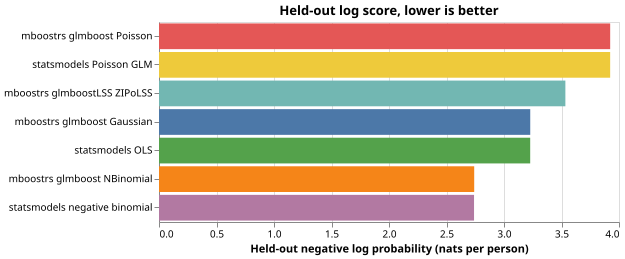

In [5]:
alt.Chart(summary).mark_bar().encode(
    x=alt.X("nll:Q", title="Held-out negative log probability (nats per person)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=460,
    height=200,
    title="Held-out log score, lower is better",
)

## Results and interpretation

Publish the negative binomial, not the Poisson. On the held-out people the negative-binomial GLM has mean absolute error {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels negative binomial')['mae'][0]):.2f}"` visits and log score {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels negative binomial')['nll'][0]):.3f}"` nats per person. The Poisson GLM is essentially the same point forecast, {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels Poisson GLM')['mae'][0]):.2f}"` visits off, and a much worse distribution: {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels Poisson GLM')['nll'][0]):.2f}"` nats. The Pearson dispersion on the refit sample is {eval}`f"{pearson_dispersion:.1f}"`, so the Poisson variance assumption is already false before the holdout is scored. The negative-binomial dispersion is alpha {eval}`f"{negbin_alpha:.2f}"` (variance `mu + alpha mu^2`). Its coefficient on the number of chronic conditions is {eval}`f"{float(negbin.params['chronic']):.2f}"` on the log mean.

The held-out sample has zero visits for {eval}`f"{zero_share:.1%}"` of people. The Poisson GLM puts that probability at {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels Poisson GLM')['p0'][0]):.1%}"`. The negative binomial puts it at {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels negative binomial')['p0'][0]):.1%}"`. The zero-inflated Poisson, with steps chosen on the validation people, has mean extra-zero probability {eval}`f"{zip_sigma:.2f}"` and a holdout log score of {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboostLSS ZIPoLSS')['nll'][0]):.2f}"`. An extra point mass at zero does not repair a Poisson tail. Do not publish it in place of the negative binomial.

OLS and the boosted Gaussian are the baselines that ignore the count support. Their holdout log scores are {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels OLS')['nll'][0]):.2f}"` and {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost Gaussian')['nll'][0]):.2f}"`. OLS has the smallest absolute error, {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels OLS')['mae'][0]):.2f}"` visits, against {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels negative binomial')['mae'][0]):.2f}"` for the negative binomial. A mean-only comparison would not have changed the tariff. The Gaussian has no probability of an exact zero and can put mass on a negative count. It is not an allowance distribution.

Boosting the same six columns does not move the decision. The boosted negative binomial stops at {eval}`str(int(summary.filter(pl.col('method')=='mboostrs glmboost NBinomial')['mstop'][0]))` steps with log score {eval}`f"{float(summary.filter(pl.col('method')=='mboostrs glmboost NBinomial')['nll'][0]):.3f}"`, next to the GLM rather than ahead of it. Use the statsmodels negative binomial when a closed form is required. The number is physician office visits, not total medical use.


In [6]:
poisson_boost = boosted["mboostrs glmboost Poisson"]["fit"]
train_mu = np.asarray(poisson_boost.predict(fit_rows, type="response"), dtype=float).ravel()
poisson_ll_gap = abs(
    float(poisson_boost.logLik())
    - float(stats.poisson.logpmf(fit_rows["visits"].to_numpy(), np.clip(train_mu, 1e-8, None)).sum())
)
nb_boost = boosted["mboostrs glmboost NBinomial"]["fit"]
nb_mu = np.asarray(nb_boost.predict(fit_rows, type="response"), dtype=float).ravel()
nb_size_fit = float(np.asarray(nb_boost.nuisance()).ravel()[0])
nb_scipy = stats.nbinom.logpmf(
    fit_rows["visits"].to_numpy(),
    nb_size_fit,
    nb_size_fit / (nb_size_fit + np.clip(nb_mu, 1e-8, None)),
).sum()
nb_ll_gap = abs(float(nb_boost.logLik()) - float(nb_scipy))
zip_fit = boosted["mboostrs glmboostLSS ZIPoLSS"]["fit"]
zip_pred = zip_fit.predict(type="response")
zip_finite = bool(np.isfinite(np.asarray(zip_pred["mu"])).all() and np.isfinite(np.asarray(zip_pred["sigma"])).all())
try:
    mb.glmboost(
        "visits ~ C(health)",
        raw,
        family=mb.Poisson(),
        control=mb.boost_control(5, 0.1),
    )
    factor_message = "accepted"
except Exception as exc:
    factor_message = str(exc).split("\n")[0]
print("poisson logLik gap", poisson_ll_gap)
print("nb logLik gap", nb_ll_gap, "size", nb_size_fit)
print("zip finite", zip_finite, "at_cap", boosted["mboostrs glmboostLSS ZIPoLSS"]["at_cap"])
print("C(health):", factor_message)

poisson logLik gap 2.3646862246096134e-11
nb logLik gap 7.275957614183426e-12 size 1.1413396469710828
zip finite True at_cap False
C(health): C(health) is a categorical column with 3 levels. Encoding it as numbers would make C treat the levels as an ordered measurement. In gamboost, bols(health) fits one effect per level (with intercept=, df= or lambda= as in mboost); brandom(health) fits them with a ridge penalty; otherwise expand the column into indicator columns yourself.


## API behavior and limitations

`glmboost` will not take `C(health)` on the character column. The refusal is that a categorical column has to be expanded, or passed to `bols` / `brandom` in `gamboost`, because numeric codes would be read as an ordered measurement. The indicators above are built in Polars before the formula. `predict` with no `type` is the log mean for Poisson and `NBinomial`; the scores use `type="response"`.

`NBinomial.nuisance()` is the negative-binomial size, not statsmodels' alpha. The variance is `mu + mu**2 / size`, so alpha is `1 / size`. On this refit the size is {eval}`f"{nb_size_fit:.3f}"` and `1 / size` is {eval}`f"{1 / nb_size_fit:.3f}"`, next to the GLM's alpha of {eval}`f"{negbin_alpha:.3f}"`. `logLik()` matches a SciPy negative binomial with that size to {eval}`f"{nb_ll_gap:.1e}"`. Reading `nuisance()` as alpha scores the wrong density. The Poisson `logLik()` matches SciPy to {eval}`f"{poisson_ll_gap:.1e}"`.

`ZIPoLSS` `predict(type="response")` returns the Poisson mean `mu` and the extra-zero probability `sigma`. The mean of the visits, which is what the absolute error uses, is `(1 - sigma) * mu`, not `mu`. `sigma` is not a dispersion. A noncyclic path takes its stopping rule as one total, not a per-parameter pair; asking for an even split raises. The zero-inflated predictions on the refit sample are finite: {eval}`str(zip_finite)`.

`negativebinomial` converged: {eval}`str(negbin_converged)`. Alpha near 1 is overdispersion, not a failure to fit.
